# 05 - Failure risk: from predicted RUL to HIGH / MEDIUM / LOW

| Level | Rule |
|---|---|
| **HIGH** | P(fails within 30 cycles) ≥ 0.5 |
| **MEDIUM** | P(fails within 60 cycles) ≥ 0.5 |
| **LOW** | otherwise |

The probability comes from a logistic regression fitted on the **validation** engines. Test engines are used once, at the end.

In [1]:
H = 30          # warning horizon (cycles)
P_CUT = 0.5     # "more likely than not"

## 1. Train the model (same as 02_baselines) and predict

In [2]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from aerohealth import summarize, train_xgb

d = np.load("../data/processed/fd001_windows.npz")
y_val, y_test = d["y_val"], d["y_test"]

model = train_xgb(summarize(d["X_tr"]), d["y_tr"])
p_val = model.predict(summarize(d["X_val"]))      # validation windows
p_test = model.predict(summarize(d["X_test"]))    # 100 test engines

## 2. Why not simply "HIGH if predicted RUL ≤ 30"?
Error = predicted − true. **Positive = late** (the model gives the engine more life than it really has).

In [3]:
err = p_val - y_val
for lo, hi in [(0, 15), (15, 30), (30, 45), (45, 60), (60, 90), (90, 126)]:
    e = err[(y_val >= lo) & (y_val < hi)]
    print(f"true RUL {lo}-{min(hi, 125)}: {len(e)} windows, RMSE {np.sqrt(np.mean(e ** 2)):.2f}, "
          f"mean error {e.mean():+.2f}, late {np.mean(e > 0):.0%}")

true RUL 0-15: 300 windows, RMSE 3.33, mean error +1.43, late 69%
true RUL 15-30: 300 windows, RMSE 6.21, mean error +2.27, late 67%
true RUL 30-45: 300 windows, RMSE 9.53, mean error +3.56, late 59%
true RUL 45-60: 300 windows, RMSE 12.93, mean error +3.11, late 52%
true RUL 60-90: 600 windows, RMSE 18.65, mean error +8.71, late 64%
true RUL 90-125: 1690 windows, RMSE 11.99, mean error -5.65, late 24%


**Reading:** near failure the model is accurate but **late about 2 times in 3**, so we calibrate instead of using a fixed rule.

## 3. Calibrate: predicted RUL → probability of failure
Label = 1 if the engine really fails within the horizon. One model for 30 cycles (HIGH), one for 60 (MEDIUM).

HIGH   if predicted RUL <= 31.6
MEDIUM if predicted RUL <= 63.3


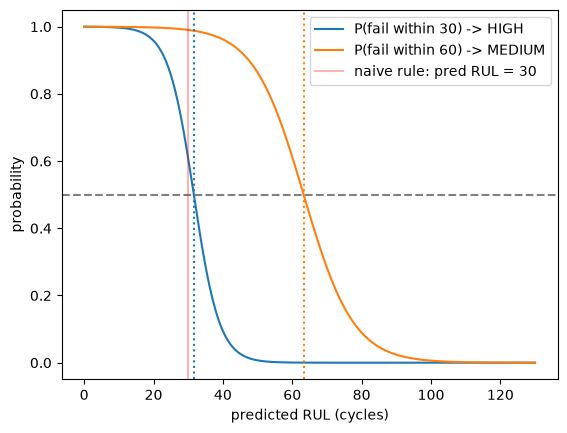

In [4]:
X = p_val.reshape(-1, 1)                          # sklearn wants a 2D input
cal_H = LogisticRegression(C=1e6, max_iter=1000).fit(X, y_val <= H)
cal_2H = LogisticRegression(C=1e6, max_iter=1000).fit(X, y_val <= 2 * H)

# P = 1 / (1 + exp(-(a + b * RUL))) is exactly 0.5 where a + b * RUL = 0, i.e. RUL = -a / b
cut_H = -cal_H.intercept_[0] / cal_H.coef_[0, 0]
cut_2H = -cal_2H.intercept_[0] / cal_2H.coef_[0, 0]
print(f"HIGH   if predicted RUL <= {cut_H:.1f}")
print(f"MEDIUM if predicted RUL <= {cut_2H:.1f}")

rul = np.linspace(0, 130, 300).reshape(-1, 1)
plt.plot(rul, cal_H.predict_proba(rul)[:, 1], label="P(fail within 30) -> HIGH")
plt.plot(rul, cal_2H.predict_proba(rul)[:, 1], label="P(fail within 60) -> MEDIUM")
plt.axhline(0.5, ls="--", c="grey")
plt.axvline(cut_H, ls=":", c="C0")
plt.axvline(cut_2H, ls=":", c="C1")
plt.axvline(H, c="red", alpha=0.3, label="naive rule: pred RUL = 30")
plt.xlabel("predicted RUL (cycles)"); plt.ylabel("probability"); plt.legend()
plt.savefig("../results/failure_risk_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading:** the HIGH cut-off is 31.6, a little above 30: the calibration corrects the late bias, so engines are flagged slightly earlier.

## 4. Apply to the test engines (once, nothing is fitted here)

In [5]:
P_H = cal_H.predict_proba(p_test.reshape(-1, 1))[:, 1]       # P(fail within 30)
P_2H = cal_2H.predict_proba(p_test.reshape(-1, 1))[:, 1]     # P(fail within 60)
risk = np.where(P_H >= P_CUT, "HIGH", np.where(P_2H >= P_CUT, "MEDIUM", "LOW"))

truth = np.where(y_test <= 30, "fails within 30", np.where(y_test <= 60, "30 to 60", "over 60"))
print(pd.crosstab(risk, truth, rownames=["risk"], colnames=["true RUL"]).loc[["HIGH", "MEDIUM", "LOW"], ["fails within 30", "30 to 60", "over 60"]])

fails = y_test <= H
print("\nengines failing within 30:", fails.sum())
print("  rated HIGH:", (fails & (risk == "HIGH")).sum(), "| rated LOW:", (fails & (risk == "LOW")).sum())
print("HIGH engines that really fail within 30:", (fails & (risk == "HIGH")).sum(), "of", (risk == "HIGH").sum())

true RUL  fails within 30  30 to 60  over 60
risk                                        
HIGH                   23         1        0
MEDIUM                  2         6        2
LOW                     0         7       59

engines failing within 30: 25
  rated HIGH: 23 | rated LOW: 0
HIGH engines that really fail within 30: 23 of 24


In [6]:
table = pd.DataFrame({"engine": np.arange(1, 101), "pred_RUL": p_test.astype(float).round(1),
                      "P_fail_30": P_H.round(3), "P_fail_60": P_2H.round(3), "risk_level": risk, "true_RUL": y_test.astype(int)})
table.to_csv("../results/failure_risk_xgb.csv", index=False)
table.sort_values("P_fail_30", ascending=False).head(10)

,engine,pred_RUL,P_fail_30,P_fail_60,risk_level,true_RUL
67,68,7.0,0.999,1.000,HIGH,8
33,34,7.2,0.999,1.000,HIGH,7
30,31,9.1,0.998,0.999,HIGH,8
81,82,8.3,0.998,1.000,HIGH,9
80,81,8.3,0.998,1.000,HIGH,8
75,76,8.0,0.998,1.000,HIGH,10
19,20,11.1,0.996,0.999,HIGH,16
41,42,12.2,0.995,0.999,HIGH,10
48,49,12.6,0.994,0.999,HIGH,21
55,56,16.8,0.982,0.998,HIGH,15


**Reading:** 23 of the 25 engines that fail within 30 cycles are HIGH, the other 2 MEDIUM, and **none is LOW**.

## Extra (for viva questions): why H = 30 and P_CUT = 0.5?
Checked on validation windows. **Recall** = failing windows that get flagged. **Precision** = flags that are correct.

In [7]:
fails = y_val <= H
print("Other horizons H:")
for h in [15, 20, 30, 45, 60]:
    cal = LogisticRegression(C=1e6, max_iter=1000).fit(X, y_val <= h)
    flag = cal.predict_proba(X)[:, 1] >= 0.5
    real = y_val <= h
    print(f"  H = {h}: cut-off {-cal.intercept_[0] / cal.coef_[0, 0]:.2f}, "
          f"recall {(flag & real).sum() / real.sum():.2f}, precision {(flag & real).sum() / flag.sum():.2f}, "
          f"failing test engines {(y_test <= h).sum()}")

print("Other probability cut-offs (H = 30):")
a, b = cal_H.intercept_[0], cal_H.coef_[0, 0]
P_val = cal_H.predict_proba(X)[:, 1]
for pc in [0.2, 0.3, 0.5, 0.7, 0.8]:
    flag = P_val >= pc
    print(f"  P_CUT = {pc}: cut-off {(np.log(pc / (1 - pc)) - a) / b:.2f}, "
          f"recall {(flag & fails).sum() / fails.sum():.2f}, precision {(flag & fails).sum() / flag.sum():.2f}, "
          f"missed {(~flag & fails).sum()}, false alarms {(flag & ~fails).sum()}")

Other horizons H:
  H = 15: cut-off 16.90, recall 0.91, precision 0.91, failing test engines 10
  H = 20: cut-off 21.71, recall 0.92, precision 0.93, failing test engines 16
  H = 30: cut-off 31.62, recall 0.93, precision 0.92, failing test engines 25
  H = 45: cut-off 47.06, recall 0.91, precision 0.90, failing test engines 28
  H = 60: cut-off 63.28, recall 0.92, precision 0.92, failing test engines 39
Other probability cut-offs (H = 30):
  P_CUT = 0.2: cut-off 36.76, recall 0.97, precision 0.84, missed 17, false alarms 118
  P_CUT = 0.3: cut-off 34.76, recall 0.96, precision 0.86, missed 24, false alarms 96
  P_CUT = 0.5: cut-off 31.62, recall 0.93, precision 0.92, missed 43, false alarms 50
  P_CUT = 0.7: cut-off 28.47, recall 0.87, precision 0.98, missed 79, false alarms 10
  P_CUT = 0.8: cut-off 26.47, recall 0.82, precision 0.99, missed 111, false alarms 4


**Reading:** every H works about equally well (recall and precision about 0.9). We pick 30 because it leaves 25 failing
test engines to evaluate (only 10 at H = 15) and is a useful warning time. A lower P_CUT misses fewer failures but raises
more false alarms; 0.5 means "more likely than not".